
# Random Forest V2 — Training and Evaluation

## NLP-Assisted Symptom-Based Disease Prediction System

This notebook presents the training configuration and evaluation of the V2 Random Forest model developed to classify 23 respiratory conditions.

The model was trained using DDXPlus-derived scenarios for 21 respiratory conditions, supplemented with synthetic scenarios for COVID-19 and allergic rhinitis.

The notebook covers:

1. Model configuration and training summary
2. Classification performance
3. Per-condition precision, recall and F1-score
4. Confusion matrices
5. Feature importance
6. Model limitations

**Note:** The model is a research prototype for preliminary health awareness, not a clinical diagnostic tool. Independent clinical validation has not been performed.


In [8]:

# Import libraries and load the trained V2 model

from pathlib import Path
import json
import tempfile

import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Find project root
ROOT = next(
    parent
    for parent in [Path.cwd(), *Path.cwd().parents]
    if (parent / "models/v2_feature_schema.json").exists()
)

MODEL_DIR = ROOT / "models"

RESULTS_DIR = ROOT / "reports" / "validation_v2_23class"

model_path = MODEL_DIR / "rf_v2_23class_prototype.joblib"

manifest_path = (
    MODEL_DIR / "rf_v2_23class_prototype_manifest.json"
)

metrics_path = RESULTS_DIR / "validation_metrics.json"

# Check required files
for path in [model_path, manifest_path, metrics_path]:
    assert path.is_file(), f"Missing file: {path}"

# Load saved model and results
model = joblib.load(model_path)

manifest = json.loads(
    manifest_path.read_text(encoding="utf-8")
)

metrics = json.loads(
    metrics_path.read_text(encoding="utf-8")
)

print("RANDOM FOREST V2 - MODEL SUMMARY")
print("--------------------------------------")
print("Model:", type(model).__name__)
print("Conditions:", len(model.classes_))
print("Features:", len(model.feature_names_in_))
print("Training scenarios:", manifest["training_count"])
print("Random Forest trees:", model.n_estimators)

print("\nVALIDATION SUMMARY")
print("--------------------------------------")
print("Validation records:", metrics["validation_records"])
print("True validation conditions:", metrics["true_conditions"])
print("Prediction classes:", metrics["prediction_classes"])
print(f"Accuracy: {metrics['accuracy']:.4f}")
print(f"Macro F1-score: {metrics['macro_f1_21']:.4f}")

print("\nModel and evaluation results loaded successfully!")


RANDOM FOREST V2 - MODEL SUMMARY
--------------------------------------
Model: RandomForestClassifier
Conditions: 23
Features: 66
Training scenarios: 41061
Random Forest trees: 180

VALIDATION SUMMARY
--------------------------------------
Validation records: 55808
True validation conditions: 21
Prediction classes: 23
Accuracy: 0.8934
Macro F1-score: 0.8642

Model and evaluation results loaded successfully!



## 1. Random Forest Classification Performance

The Random Forest model was evaluated using the DDXPlus validation dataset containing 55,808 scenarios from the original 21 respiratory conditions.

The model was evaluated using accuracy, macro precision, macro recall and macro F1-score.

Although the trained model supports 23 conditions, the validation dataset contains no independently labelled COVID-19 or allergic-rhinitis cases. Therefore, these results describe performance on the original 21 conditions only.


RANDOM FOREST VALIDATION PERFORMANCE
-------------------------------------
         Metric  Score  Percentage (%)
       Accuracy 0.8934           89.34
Macro Precision 0.8748           87.48
   Macro Recall 0.8787           87.87
 Macro F1-score 0.8642           86.42


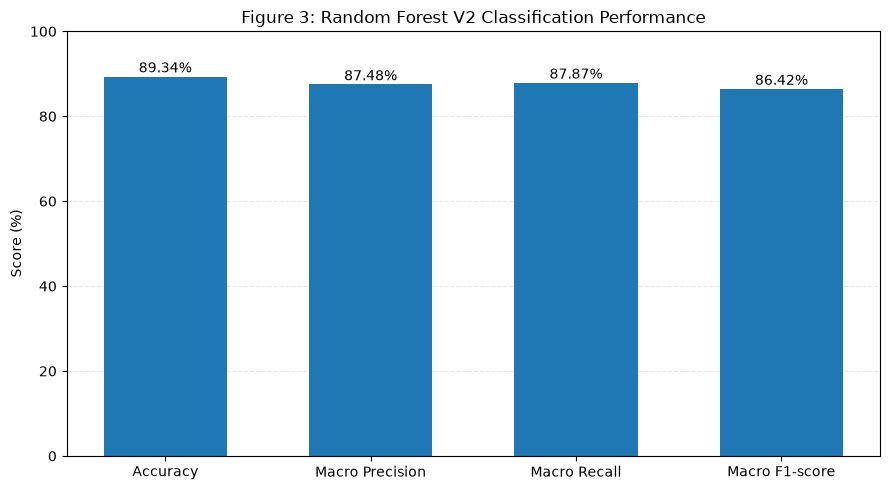


Figure 3 generated successfully.
Evaluation: DDXPlus validation (21 true conditions).
Independent COVID-19/rhinitis validation: NOT PERFORMED.


In [2]:

# Figure 3: Random Forest classification performance

performance = {
    "Accuracy": metrics["accuracy"],
    "Macro Precision": metrics["macro_precision_21"],
    "Macro Recall": metrics["macro_recall_21"],
    "Macro F1-score": metrics["macro_f1_21"]
}

performance_df = pd.DataFrame({
    "Metric": list(performance.keys()),
    "Score": list(performance.values()),
})

performance_df["Percentage (%)"] = (
    performance_df["Score"] * 100
).round(2)

print("RANDOM FOREST VALIDATION PERFORMANCE")
print("-------------------------------------")
print(
    performance_df.to_string(
        index=False,
        formatters={"Score": "{:.4f}".format}
    )
)

# Generate bar chart
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    performance_df["Metric"],
    performance_df["Percentage (%)"],
    width=0.6
)

ax.set_title(
    "Figure 3: Random Forest V2 Classification Performance"
)

ax.set_ylabel("Score (%)")
ax.set_ylim(0, 100)

# Add values above the bars
for bar, value in zip(
    bars,
    performance_df["Percentage (%)"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center",
        fontsize=10
    )

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

print("\nFigure 3 generated successfully.")
print("Evaluation: DDXPlus validation (21 true conditions).")
print("Independent COVID-19/rhinitis validation: NOT PERFORMED.")



## 2. Per-Condition Classification Results

The performance of the Random Forest model was examined separately for each of the 21 conditions represented in the DDXPlus validation dataset.

Precision measures how many predictions for a condition were correct, while recall measures how many actual cases of that condition were correctly identified. The F1-score combines precision and recall into a single measure.

The results help identify conditions that the model predicts well and conditions that are frequently confused with similar respiratory illnesses.

COVID-19 and allergic rhinitis are excluded from this per-condition validation report because independently labelled validation cases were not available for them.


PER-CONDITION CLASSIFICATION REPORT
-----------------------------------


,precision,recall,f1-score,support
Bronchiolitis,0.263,0.893,0.407,28
Acute rhinosinusitis,0.602,0.559,0.580,1866
Bronchospasm / acute asthma exacerbation,0.781,0.509,0.616,2209
Acute COPD exacerbation / infection,0.620,0.796,0.697,2076
Chronic rhinosinusitis,0.723,0.694,0.708,2717
Allergic sinusitis,1.000,0.685,0.813,2136
Bronchiectasis,0.947,0.758,0.842,2319
Bronchitis,0.829,0.897,0.862,3543
Tuberculosis,0.909,0.913,0.911,2007
Acute laryngitis,0.999,0.859,0.924,3407


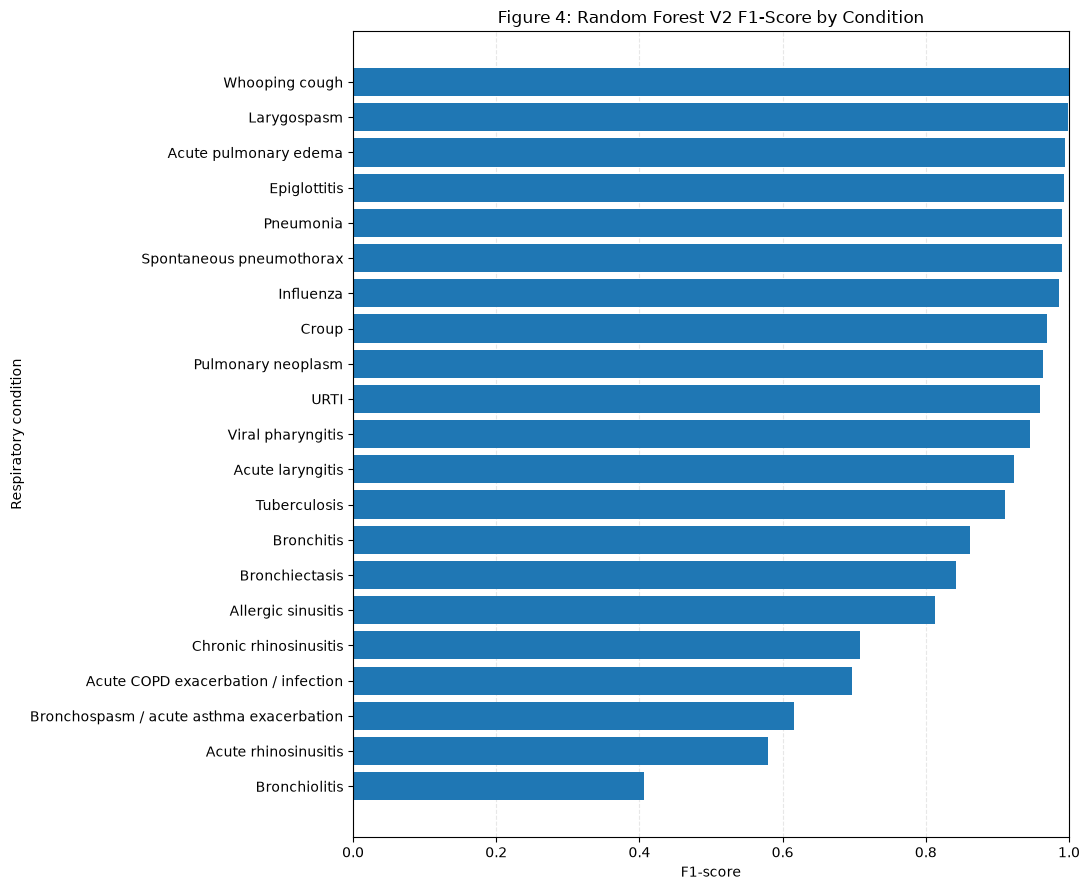


LOWEST 5 F1-SCORES
-----------------------------------
                                          precision  recall  f1-score  support
Bronchiolitis                                0.2632  0.8929    0.4065       28
Acute rhinosinusitis                         0.6024  0.5595    0.5802     1866
Bronchospasm / acute asthma exacerbation     0.7807  0.5093    0.6164     2209
Acute COPD exacerbation / infection          0.6203  0.7962    0.6973     2076
Chronic rhinosinusitis                       0.7231  0.6938    0.7081     2717

Figure 4 generated successfully.
Validated conditions: 21
COVID-19 and allergic rhinitis: Not independently validated


In [3]:

# Figure 4: Per-condition F1-scores

from IPython.display import display

report_path = RESULTS_DIR / "classification_report.csv"

assert report_path.is_file(), "Classification report not found"

report = pd.read_csv(
    report_path,
    index_col=0
)

# Only the 21 conditions with actual validation labels
new_conditions = ["COVID-19", "Allergic rhinitis"]

original_conditions = [
    name for name in model.classes_
    if name not in new_conditions
]

per_class = report.loc[
    original_conditions,
    ["precision", "recall", "f1-score", "support"]
].copy()

assert len(per_class) == 21
assert int(per_class["support"].sum()) == 55808

per_class["support"] = per_class["support"].astype(int)

print("PER-CONDITION CLASSIFICATION REPORT")
print("-----------------------------------")

display(
    per_class.sort_values("f1-score").round(3)
)

# Plot F1-score for each condition
plot_data = per_class.sort_values("f1-score")

fig, ax = plt.subplots(figsize=(11, 9))

bars = ax.barh(
    plot_data.index,
    plot_data["f1-score"]
)

ax.set_title(
    "Figure 4: Random Forest V2 F1-Score by Condition"
)

ax.set_xlabel("F1-score")
ax.set_ylabel("Respiratory condition")
ax.set_xlim(0, 1)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

print("\nLOWEST 5 F1-SCORES")
print("-----------------------------------")

print(
    per_class.sort_values("f1-score")
    .head(5)
    .round(4)
    .to_string()
)

print("\nFigure 4 generated successfully.")
print("Validated conditions: 21")
print("COVID-19 and allergic rhinitis: Not independently validated")



## 3. Confusion Matrix Analysis

A confusion matrix was used to examine the classification results of the Random Forest model.

The rows represent the actual respiratory conditions, while the columns represent the predicted conditions. Values along the main diagonal indicate correct predictions, while values outside the diagonal indicate misclassifications.

The validation dataset contains 21 actual respiratory conditions, but the model can predict all 23 conditions. Therefore, the confusion matrix includes 21 actual-condition rows and 23 predicted-condition columns.

The raw confusion matrix shows the number of correctly and incorrectly classified scenarios for each condition.


RAW CONFUSION MATRIX
-----------------------------------
Actual conditions: 21
Predicted conditions: 23
Total validation scenarios: 55808


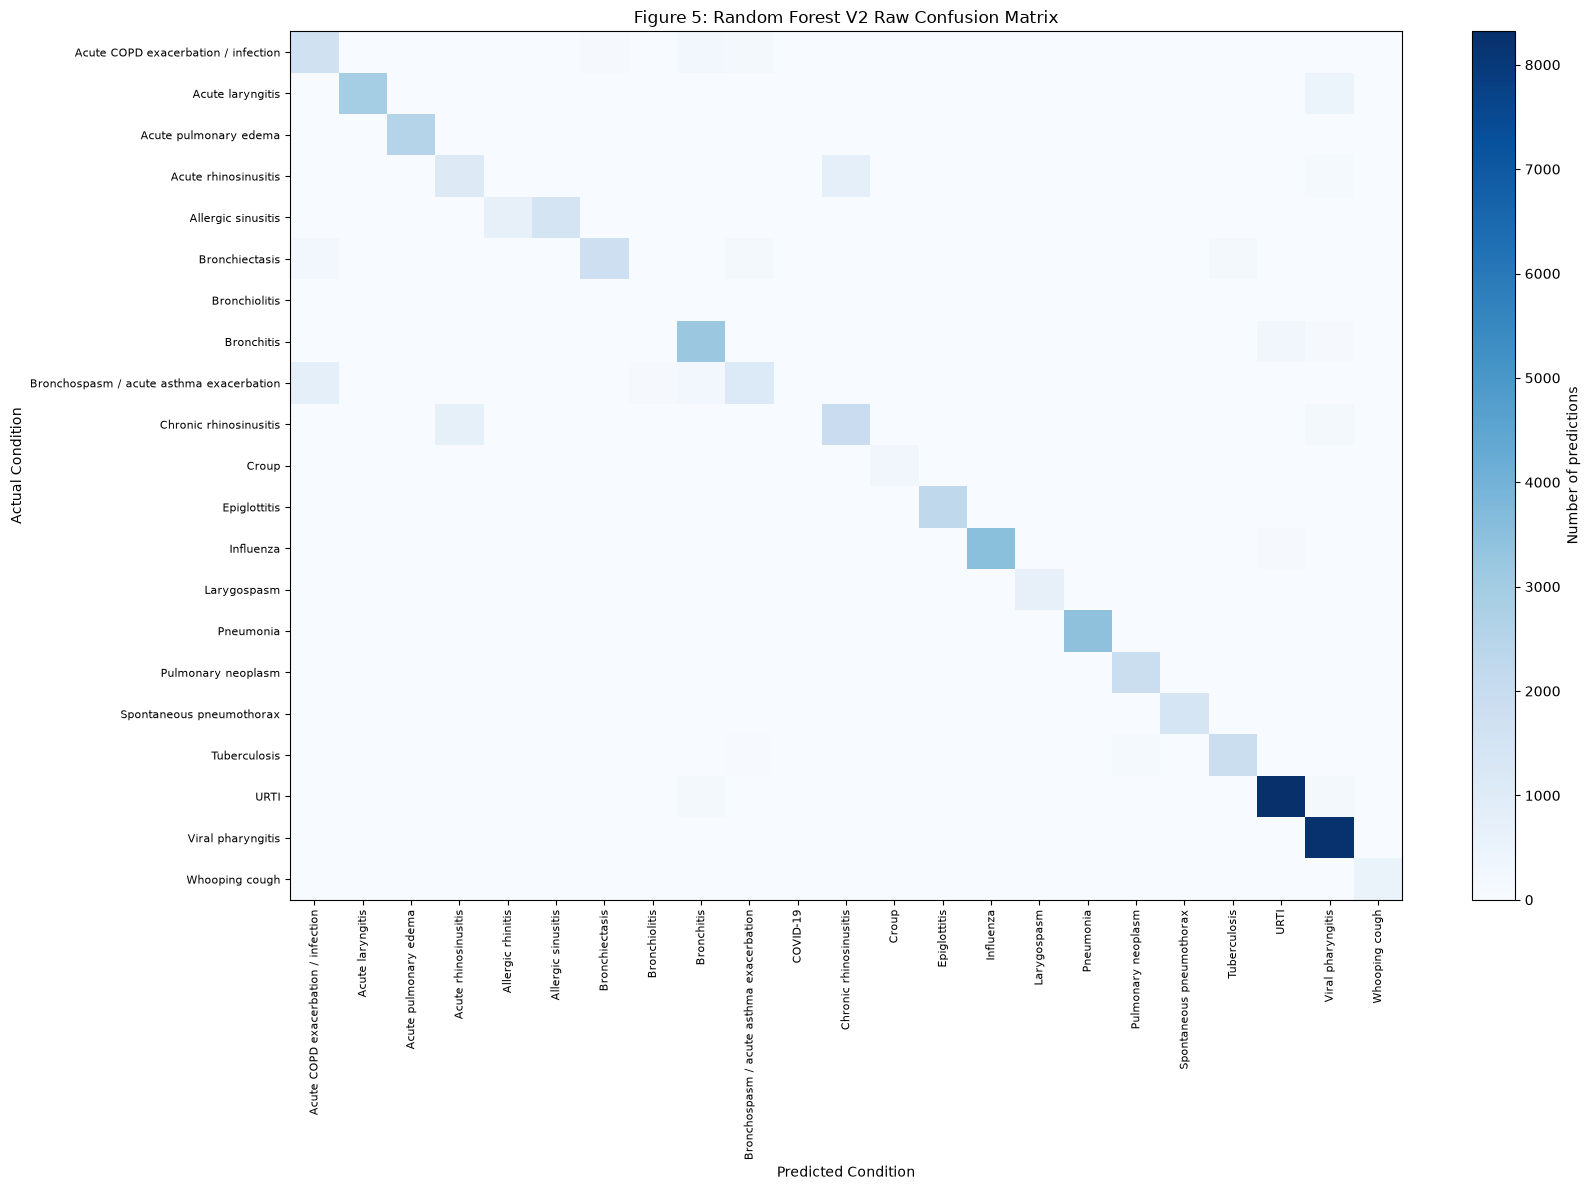


SELECTED MISCLASSIFICATIONS
-----------------------------------
Allergic sinusitis predicted as allergic rhinitis: 660
Predictions of COVID-19: 0
Predictions of allergic rhinitis: 660

Figure 5 generated successfully.


In [4]:

# Figure 5: Raw confusion matrix

matrix_path = (
    RESULTS_DIR / "confusion_matrix_raw.csv"
)

assert matrix_path.is_file(), (
    "Raw confusion matrix not found"
)

raw_matrix = pd.read_csv(
    matrix_path,
    index_col=0
)

# All 23 model prediction classes
all_conditions = list(model.classes_)

# Only 21 conditions have actual validation cases
new_conditions = [
    "COVID-19",
    "Allergic rhinitis"
]

actual_conditions = [
    condition
    for condition in all_conditions
    if condition not in new_conditions
]

# Keep all prediction columns, including new conditions
matrix = raw_matrix.loc[
    actual_conditions,
    all_conditions
]

assert matrix.shape == (21, 23)
assert matrix.to_numpy().sum() == 55808

print("RAW CONFUSION MATRIX")
print("-----------------------------------")
print("Actual conditions:", matrix.shape[0])
print("Predicted conditions:", matrix.shape[1])
print("Total validation scenarios:", int(matrix.to_numpy().sum()))

# Generate confusion matrix heatmap
fig, ax = plt.subplots(figsize=(17, 12))

image = ax.imshow(
    matrix.to_numpy(),
    interpolation="nearest",
    aspect="auto",
    cmap="Blues"
)

fig.colorbar(
    image,
    ax=ax,
    label="Number of predictions"
)

ax.set_xticks(range(len(all_conditions)))
ax.set_yticks(range(len(actual_conditions)))

ax.set_xticklabels(
    all_conditions,
    rotation=90,
    fontsize=8
)

ax.set_yticklabels(
    actual_conditions,
    fontsize=8
)

ax.set_xlabel("Predicted Condition")
ax.set_ylabel("Actual Condition")

ax.set_title(
    "Figure 5: Random Forest V2 Raw Confusion Matrix"
)

plt.tight_layout()
plt.show()

print("\nSELECTED MISCLASSIFICATIONS")
print("-----------------------------------")

print(
    "Allergic sinusitis predicted as allergic rhinitis:",
    int(matrix.loc[
        "Allergic sinusitis",
        "Allergic rhinitis"
    ])
)

print(
    "Predictions of COVID-19:",
    int(matrix["COVID-19"].sum())
)

print(
    "Predictions of allergic rhinitis:",
    int(matrix["Allergic rhinitis"].sum())
)

print("\nFigure 5 generated successfully.")


## 4. One-vs-Rest Confusion Matrix for a Single Condition

To make the confusion matrix easier to present in the report, a one-vs-rest confusion matrix was created for one selected disease.

In this analysis, **Bronchospasm / acute asthma exacerbation** was treated as the positive class, while all other conditions were treated as the negative class.

This produces a compact 2×2 matrix showing:

- **True Positive (TP):** the selected condition correctly predicted
- **False Positive (FP):** other conditions incorrectly predicted as the selected condition
- **False Negative (FN):** the selected condition incorrectly predicted as something else
- **True Negative (TN):** all other conditions correctly predicted as not the selected condition

ONE-VS-REST CONFUSION MATRIX
--------------------------------------
Target condition: Bronchospasm / acute asthma exacerbation
Total validation cases: 55808

2x2 CONFUSION MATRIX
--------------------------------------
                                                      Predicted: Bronchospasm / acute asthma exacerbation  Predicted: Not Bronchospasm / acute asthma exacerbation
Actual: Bronchospasm / acute asthma exacerbation                                                     1125                                                     1084
Actual: Not Bronchospasm / acute asthma exacerbation                                                  316                                                    53283

SUMMARY METRICS
--------------------------------------
              Metric      Value
 True Positives (TP)  1125.0000
False Positives (FP)   316.0000
False Negatives (FN)  1084.0000
 True Negatives (TN) 53283.0000
           Precision     0.7807
Recall / Sensitivity     0.5093
         Spec

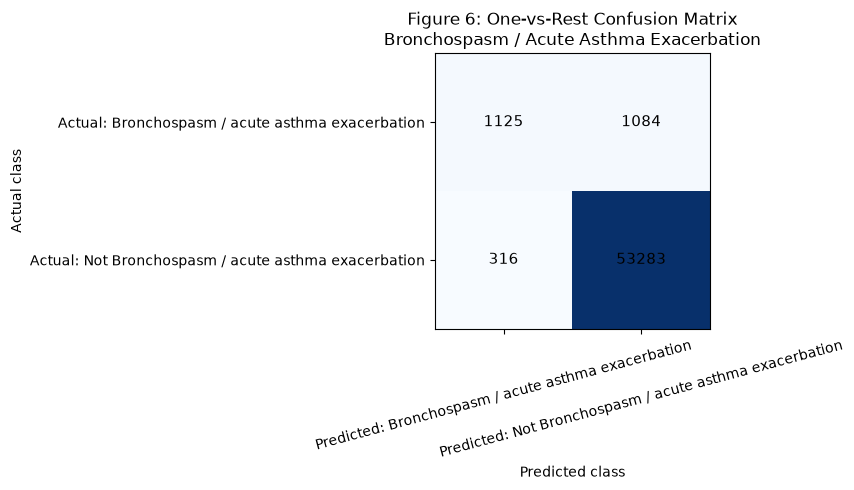


Figure 6 generated successfully.


In [5]:
# Figure 6: Small 2x2 confusion matrix for one condition

import pandas as pd
import matplotlib.pyplot as plt

target_condition = "Bronchospasm / acute asthma exacerbation"

matrix_path = RESULTS_DIR / "confusion_matrix_raw.csv"

raw_matrix = pd.read_csv(
    matrix_path,
    index_col=0
)

assert target_condition in raw_matrix.index
assert target_condition in raw_matrix.columns

total_cases = int(raw_matrix.to_numpy().sum())

tp = int(raw_matrix.loc[target_condition, target_condition])
fn = int(raw_matrix.loc[target_condition].sum() - tp)
fp = int(raw_matrix[target_condition].sum() - tp)
tn = int(total_cases - tp - fn - fp)

small_matrix = pd.DataFrame(
    [
        [tp, fn],
        [fp, tn]
    ],
    index=[
        f"Actual: {target_condition}",
        f"Actual: Not {target_condition}"
    ],
    columns=[
        f"Predicted: {target_condition}",
        f"Predicted: Not {target_condition}"
    ]
)

print("ONE-VS-REST CONFUSION MATRIX")
print("--------------------------------------")
print("Target condition:", target_condition)
print("Total validation cases:", total_cases)

print("\n2x2 CONFUSION MATRIX")
print("--------------------------------------")
print(small_matrix.to_string())

precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
fnr = fn / (fn + tp) if (fn + tp) > 0 else 0

summary = pd.DataFrame({
    "Metric": [
        "True Positives (TP)",
        "False Positives (FP)",
        "False Negatives (FN)",
        "True Negatives (TN)",
        "Precision",
        "Recall / Sensitivity",
        "Specificity",
        "False Positive Rate",
        "False Negative Rate"
    ],
    "Value": [
        tp,
        fp,
        fn,
        tn,
        round(precision, 4),
        round(recall, 4),
        round(specificity, 4),
        round(fpr, 4),
        round(fnr, 4)
    ]
})

print("\nSUMMARY METRICS")
print("--------------------------------------")
print(summary.to_string(index=False))

# Plot small heatmap
fig, ax = plt.subplots(figsize=(7, 5))

image = ax.imshow(
    small_matrix.to_numpy(),
    cmap="Blues"
)

for i in range(small_matrix.shape[0]):
    for j in range(small_matrix.shape[1]):
        ax.text(
            j, i,
            small_matrix.iloc[i, j],
            ha="center",
            va="center",
            fontsize=11
        )

ax.set_xticks(range(2))
ax.set_yticks(range(2))
ax.set_xticklabels(small_matrix.columns, rotation=15)
ax.set_yticklabels(small_matrix.index)

ax.set_title(
    "Figure 6: One-vs-Rest Confusion Matrix\nBronchospasm / Acute Asthma Exacerbation"
)
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")

plt.tight_layout()
plt.show()

print("\nFigure 6 generated successfully.")

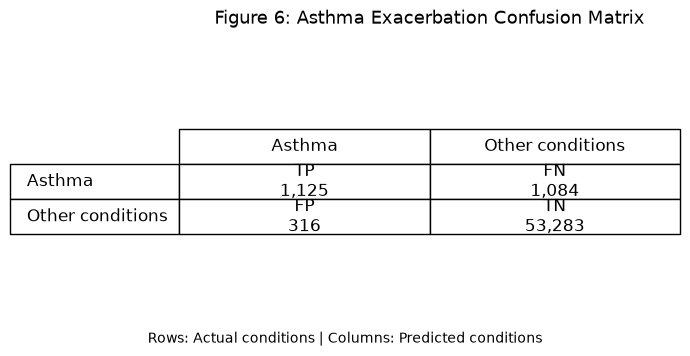

Report figure saved: c:\Users\krish\OneDrive\Desktop\IS-Project-2\ucs31-madhaparia-ml\reports\figures\figure_6_asthma_confusion_matrix.png


In [6]:

# Figure 6: Compact confusion matrix for the report

fig, ax = plt.subplots(figsize=(7, 4))
ax.axis("off")

values = [
    [f"TP\n{tp:,}", f"FN\n{fn:,}"],
    [f"FP\n{fp:,}", f"TN\n{tn:,}"]
]

table = ax.table(
    cellText=values,
    rowLabels=["Asthma", "Other conditions"],
    colLabels=["Asthma", "Other conditions"],
    cellLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1, 2.5)

ax.set_title(
    "Figure 6: Asthma Exacerbation Confusion Matrix",
    fontsize=13,
    pad=20
)

fig.text(
    0.5, 0.08,
    "Rows: Actual conditions | Columns: Predicted conditions",
    ha="center",
    fontsize=10
)

plt.tight_layout(rect=[0, 0.12, 1, 0.95])

# Save a high-resolution image for the report
output_dir = ROOT / "reports" / "figures"
output_dir.mkdir(parents=True, exist_ok=True)

figure_path = output_dir / "figure_6_asthma_confusion_matrix.png"

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Report figure saved:", figure_path)



## 5. Random Forest Feature Importance

Feature importance was examined to identify which input features contributed most to the Random Forest predictions.

The model uses age, sex and symptom features to classify respiratory conditions. Feature importance scores indicate how much each feature contributed to reducing impurity across the decision trees.

These scores do not establish that a feature causes a particular disease. They are also not measures of clinical reliability.


TOP 10 RANDOM FOREST FEATURES
--------------------------------------
       Feature  Importance
           AGE    0.091732
E_194__present    0.065621
 E_53__present    0.053206
E_166__present    0.052660
E_214__present    0.048993
E_212__present    0.046222
 E_77__present    0.042359
 E_66__present    0.036304
E_220__present    0.035933
 E_91__present    0.034275


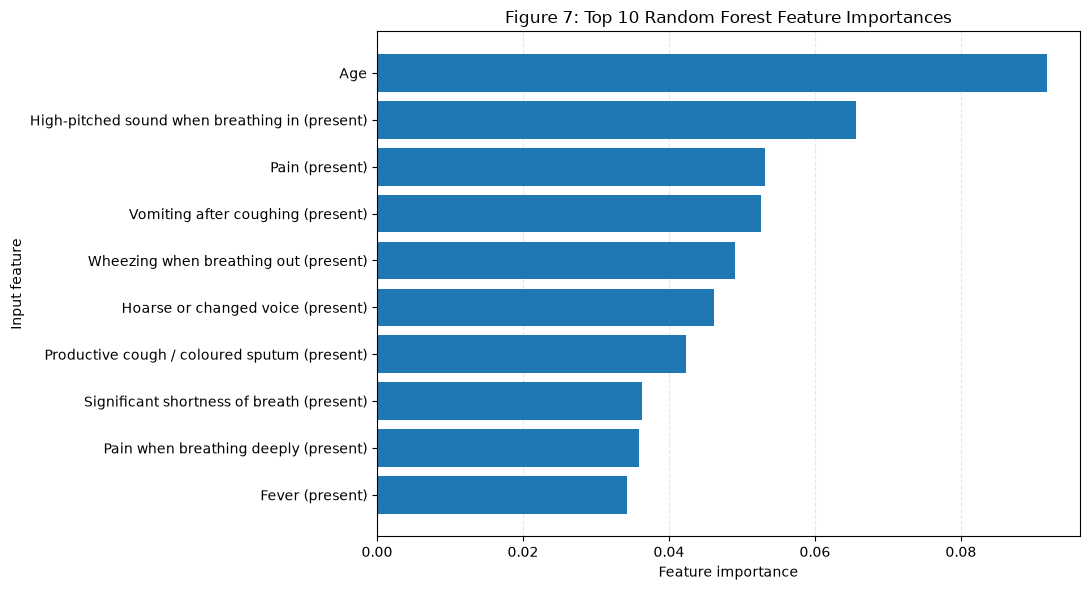


Figure 7 generated successfully.
Report figure saved: c:\Users\krish\OneDrive\Desktop\IS-Project-2\ucs31-madhaparia-ml\reports\figures\figure_7_feature_importance.png


In [7]:

# Figure 7: Top 10 Random Forest features

importance_path = RESULTS_DIR / "feature_importance.csv"

assert importance_path.is_file(), "Feature importance file not found"

importance_df = pd.read_csv(importance_path)

assert {"Feature", "Importance"}.issubset(
    importance_df.columns
)

top_features = (
    importance_df
    .sort_values("Importance", ascending=False)
    .head(10)
    .sort_values("Importance")
)

# Friendly names for report presentation
feature_labels = {
    "AGE": "Age",
    "SEX_M": "Sex (male)",
    "E_194": "High-pitched sound when breathing in",
    "E_53": "Pain",
    "E_166": "Vomiting after coughing",
    "E_214": "Wheezing when breathing out",
    "E_212": "Hoarse or changed voice",
    "E_77": "Productive cough / coloured sputum",
    "E_66": "Significant shortness of breath",
    "E_220": "Pain when breathing deeply",
    "E_91": "Fever"
}

def readable_name(feature):
    if feature in feature_labels:
        return feature_labels[feature]

    for suffix in ["__present", "__absent"]:
        if feature.endswith(suffix):
            code = feature.replace(suffix, "")
            name = feature_labels.get(code, code)
            status = "present" if suffix == "__present" else "absent"
            return f"{name} ({status})"

    return feature

labels = [
    readable_name(feature)
    for feature in top_features["Feature"]
]

print("TOP 10 RANDOM FOREST FEATURES")
print("--------------------------------------")

print(
    importance_df
    .sort_values("Importance", ascending=False)
    .head(10)
    .to_string(index=False)
)

fig, ax = plt.subplots(figsize=(11, 6))

ax.barh(
    labels,
    top_features["Importance"]
)

ax.set_title(
    "Figure 7: Top 10 Random Forest Feature Importances"
)

ax.set_xlabel("Feature importance")
ax.set_ylabel("Input feature")

ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

# Save for the final report
output_dir = ROOT / "reports" / "figures"
output_dir.mkdir(parents=True, exist_ok=True)

figure_path = (
    output_dir / "figure_7_feature_importance.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFigure 7 generated successfully.")
print("Report figure saved:", figure_path)



## 6. Model Limitations

Although the Random Forest model supports 23 respiratory conditions, several limitations were identified.

**Dataset limitations:** The original 21 conditions were represented by DDXPlus-derived scenarios. COVID-19 and allergic rhinitis were added using 800 reference-guided synthetic scenarios. These additional examples were not obtained from real Kenyan patients.

**Evaluation limitations:** The model achieved 89.34% accuracy and a macro F1-score of 86.42% on 55,808 DDXPlus validation scenarios covering the original 21 conditions. Independent validation data was not available for COVID-19 and allergic rhinitis, so the reported performance does not establish accuracy across all 23 conditions.

**Similar symptoms:** Some respiratory conditions share symptoms, making classification difficult. For example, 660 allergic-sinusitis validation scenarios were incorrectly classified as allergic rhinitis. The model also showed lower recall for bronchospasm / acute asthma exacerbation.

**Synthetic data:** The additional scenarios were generated using assumed symptom combinations and artificial demographic values. Their inclusion supports prototype development but does not establish clinical reliability or representativeness for Kenyan patients.

**Clinical limitations:** The system provides preliminary health-awareness information rather than a confirmed medical diagnosis. Model confidence scores are not calibrated probabilities of disease, and users should seek professional medical advice before making healthcare decisions.

## 7. Conclusion

The Random Forest V2 research prototype was successfully trained to produce predictions across 23 respiratory conditions using 66 numerical features.

The model achieved 89.34% validation accuracy, with a macro precision of 87.48%, macro recall of 87.87% and macro F1-score of 86.42% on the original 21 DDXPlus conditions.

The confusion matrices helped identify classification errors, while the feature-importance analysis showed which input features contributed most to the predictions.

Overall, the model provides a foundation for integration into the NLP-Assisted Symptom-Based Disease Prediction System. Further independent evaluation, especially for COVID-19 and allergic rhinitis, is required before the model can be considered reliable for clinical use.
